# 01 – Exploratory Data Analysis

TDT4173 project – SINTEF Tokke–Vinje unit commitment

**Goal:** understand the data before modelling. Structure follows the EDA lecture and the graded EDA items:

| Graded EDA item | Section |
|---|---|
| Search domain knowledge | 2.1 |
| Understand how the data was generated | 2.2 |
| Check if the data is intuitive | 2.3 |
| Explore individual features | 3 |
| Explore pairs and groups of features | 4 |
| Clean up features | 5 |

## 0. Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "../data"
KERNEL_DIR = f"{DATA_DIR}/kernel"
EXTENDED_DIR = f"{DATA_DIR}/extended"

## 1. Load data

### 1.1 Target: unit commitment decisions

- Train: 2922 rows × 2355 columns. One row = one run (one weekly plan), one run per day from 2015-01-01 to 2022-12-31.
- Columns: `Run No`, `starttime`, `total_calculation_time` + 2352 targets (14 generators × 168 hours).
- Target values are 0/1 (off/on). In the first days of 2015, Hogga G1 is on in every hour shown.
- `total_calculation_time` (~40–56 s) is not available for test → cannot be used as a feature.
- Test: 725 rows × 2353 columns (`Run No` + the same 2352 targets, filled with 0 as a template).


In [3]:
train = pd.read_csv(f"{KERNEL_DIR}/Unit_commitment_decisions.csv", parse_dates=["starttime"])
test = pd.read_csv("../sample_submission.csv")

print(train.shape, test.shape)
train.head()

(2922, 2355) (725, 2353)


,Run No,starttime,total_calculation_time,result_committed_Hogga_G1_t0,result_committed_Hogga_G1_t1,result_committed_Hogga_G1_t2,result_committed_Hogga_G1_t3,result_committed_Hogga_G1_t4,result_committed_Hogga_G1_t5,result_committed_Hogga_G1_t6,...,result_committed_Vesle Kjela_G1_t158,result_committed_Vesle Kjela_G1_t159,result_committed_Vesle Kjela_G1_t160,result_committed_Vesle Kjela_G1_t161,result_committed_Vesle Kjela_G1_t162,result_committed_Vesle Kjela_G1_t163,result_committed_Vesle Kjela_G1_t164,result_committed_Vesle Kjela_G1_t165,result_committed_Vesle Kjela_G1_t166,result_committed_Vesle Kjela_G1_t167
0,1,2015-01-01,48.950692,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,2015-01-02,56.048899,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
2,3,2015-01-03,44.280307,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
3,4,2015-01-04,40.848453,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
4,5,2015-01-05,44.036279,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0


### 1.2 Kernel features (price, inflow, volume, water value)

- Price: hourly, 2015–2025, one column (EUR/MWh).
- Inflow: hourly, 1958–2025, 17 reservoirs + 1 river. Long history, useful for seeing "normal years".
- Volume: daily, 2015–2024, 17 reservoirs.
- Water value: daily, 2015–2024, 17 reservoirs (synthetic, i.e. model-generated).
- Different time resolutions (hourly vs. daily) → must be aligned later.
- TODO: check that all tables cover the whole test period (until ~2024-12-31).

In [4]:
# Day-ahead price (hourly, EUR/MWh)
price = pd.read_csv(f"{KERNEL_DIR}/Historical_day_ahead_price_2015_2025.csv", parse_dates=["date"])

# Inflow per reservoir (hourly, m³/s)
inflow = pd.read_csv(f"{KERNEL_DIR}/Historical_inflow_1958_2025.csv", parse_dates=["date"])

# Reservoir volume (daily, Mm³)
volume = pd.read_csv(f"{KERNEL_DIR}/Historical_volume_2015_2024.csv", parse_dates=["date"])

# Water value per reservoir (daily, EUR/MWh)
water_value = pd.read_csv(f"{KERNEL_DIR}/Synthetic_water_value_2015_2024.csv", parse_dates=["date"])

for name, df in {"price": price, "inflow": inflow, "volume": volume, "water_value": water_value}.items():
    print(f"{name:12s} shape={df.shape}  from {df['date'].min()} to {df['date'].max()}")

price.head(), inflow.head(), volume.head(), water_value.head()

price        shape=(103062, 2)  from 2015-01-01 00:00:00+00:00 to 2025-12-31 23:45:00+00:00
inflow       shape=(594224, 19)  from 1958-01-01 00:00:00+00:00 to 2025-10-15 07:00:00+00:00
volume       shape=(3654, 18)  from 2015-01-01 00:00:00+00:00 to 2025-01-01 00:00:00+00:00
water_value  shape=(3654, 18)  from 2015-01-01 00:00:00+00:00 to 2025-01-01 00:00:00+00:00


(                       date  Day-ahead price (EUR/MWh)
 0 2015-01-01 00:00:00+00:00                      27.07
 1 2015-01-01 01:00:00+00:00                      26.93
 2 2015-01-01 02:00:00+00:00                      26.83
 3 2015-01-01 03:00:00+00:00                      26.81
 4 2015-01-01 04:00:00+00:00                      26.97,
                        date  Langesae  Staavatn  Kjelavatn  Bordalsvatn  \
 0 1958-01-01 00:00:00+00:00      0.37      0.03       1.23          0.5   
 1 1958-01-01 01:00:00+00:00      0.37      0.03       1.23          0.5   
 2 1958-01-01 02:00:00+00:00      0.37      0.03       1.23          0.5   
 3 1958-01-01 03:00:00+00:00      0.37      0.03       1.23          0.5   
 4 1958-01-01 04:00:00+00:00      0.37      0.03       1.23          0.5   
 
    Foersvatn  Hyljelihyl  Venemo  Bitdalsvatn  Songavatn  Totak  Vaamarvatn  \
 0       0.05        0.34    0.37         1.07       4.92   3.28        0.21   
 1       0.05        0.34    0.37         1.0

### 1.3 Extended data (topology, min flow, min volume)

- min_flow: 96432 rows (hourly 2015–2025) × 6 rivers with minimum flow requirements.
- min_volume: 96432 rows × 3 reservoirs (Totak, Byrtevatn, Staavatn) with minimum level requirements.
- Both cover train and test completely.
- Topology has 5 sections: reservoir, river, plant, generator, tunnel.
- The 14 generators in the topology are exactly the same as the 14 in the target → the files match.
- The topology gives p_min/p_max, start cost, and which reservoir feeds which plant → useful for feature engineering.

In [5]:
import yaml
# Constraints (hourly)
min_flow = pd.read_csv(f"{EXTENDED_DIR}/Constraint_min_flow.csv", parse_dates=["date"])
min_volume = pd.read_csv(f"{EXTENDED_DIR}/Constraint_min_volume.csv", parse_dates=["date"])

# Topology: the physical network
with open(f"{EXTENDED_DIR}/Tokke_Vinje_topology.yaml") as f:
    topology = yaml.safe_load(f)

print(min_flow.shape, min_volume.shape)
print("Topology sections:", list(topology["model"].keys()))
print("Generators:", list(topology["model"]["generator"].keys()))

(96432, 7) (96432, 4)
Topology sections: ['reservoir', 'river', 'plant', 'generator', 'tunnel']
Generators: ['Hogga_G1', 'Tokke_G1', 'Tokke_G2', 'Tokke_G3', 'Tokke_G4', 'Lio_G1', 'Byrte_G1', 'Vinje_G1', 'Vinje_G2', 'Vinje_G3', 'Haukeli_G1', 'Songa_G1', 'Kjela_G1', 'Vesle Kjela_G1']


### 1.4 Test set / sample submission

- Test = 725 runs, Run No 2923–3647, consecutive with no gaps (3647 − 2923 + 1 = 725).
- The test file has no dates, only Run No.
- In train, Run No n = 2015-01-01 + (n−1) days. [Check: did the pattern hold? True/False]
- Using the same pattern, test covers 2023-01-01 → 2024-12-25 (the last run extends to ~2024-12-31).
- The test period directly follows train → time series split; validation should also be done in time order

In [6]:
test[["Run No"]].describe()

,Run No
count,725.00000
mean,3285.00000
std,209.43376
min,2923.00000
25%,3104.00000
50%,3285.00000
75%,3466.00000
max,3647.00000


## 2. Building intuition about the data

### 2.1 Domain knowledge

*Hydropower basics, water value (price vs. water value rule), day-ahead market (NO2), unit commitment (start costs, p_min/p_max), seasons, constraints, the Tokke–Vinje topology.*

### 2.2 How the data was generated

**Where the target comes from**
- The on/off decisions are not observed operation. They are the output of a hydropower scheduling **optimisation model** (most likely SINTEF's SHOP).
- Each `Run No` is one run of the model: given prices, inflow, start volumes, water values and constraints, it computes the most profitable on/off plan for the next **168 hours** for all 14 generators.
- Our ML model is therefore learning to **imitate an optimiser**. The targets are deterministic functions of the inputs (no human noise), but they also depend on things we do not see directly (e.g. start costs, efficiency curves, coupling between plants).

**How the runs are organised**
- One run per day: Run 1 = 2015-01-01, Run 2 = 2015-01-02, ... (verified in 2.2.2).
- Each run covers 7 days → consecutive runs **overlap** by 6 days. The same clock hour is planned by up to 7 different runs (examined in 2.2.1).
- Train = 2015–2022, test = 2023–2024. Test comes **after** train in time.

**How the input data was produced**
- Day-ahead price: real historical market prices (Nord Pool).
- Inflow and volume: historical series per reservoir.
- Water value: **synthetic**, i.e. computed by a model, not observed.
- Constraints and topology: model input describing the physical system and regulations.

**Consequences for modelling**
- **Validation must be time-based** (e.g. train 2015–2021, validate 2022). A random split would leak information because neighbouring runs share 6 of 7 days.
- `total_calculation_time` is a by-product of the optimiser and is not available for test → **not a feature**.
- Features for a run should describe the run's own 168-hour window (prices, water values, volumes at the start).

#### 2.2.1 Overlapping horizons: consistency between consecutive runs

Run *n+1* starts 24 h after run *n*, so hour `t(h+24)` in run *n* and hour `t(h)` in run *n+1* are the same clock hour. If the optimiser always made the same decision for the same hour, these would be identical.

In [7]:
gens = sorted({c.rsplit("_t", 1)[0] for c in train.columns if c.startswith("result_committed_")})
gen_names = [g.replace("result_committed_", "") for g in gens]

# Y[run, generator, hour]
Y = np.stack([train[[f"{g}_t{h}" for h in range(168)]].to_numpy() for g in gens], axis=1)
print("Y shape (runs, generators, hours):", Y.shape)

# Compare the same clock hour in run n and run n+1
same = Y[:-1, :, 24:] == Y[1:, :, :-24]
print(f"Overall agreement between consecutive runs: {same.mean():.3f}")

Y shape (runs, generators, hours): (2922, 14, 168)
Overall agreement between consecutive runs: 0.878


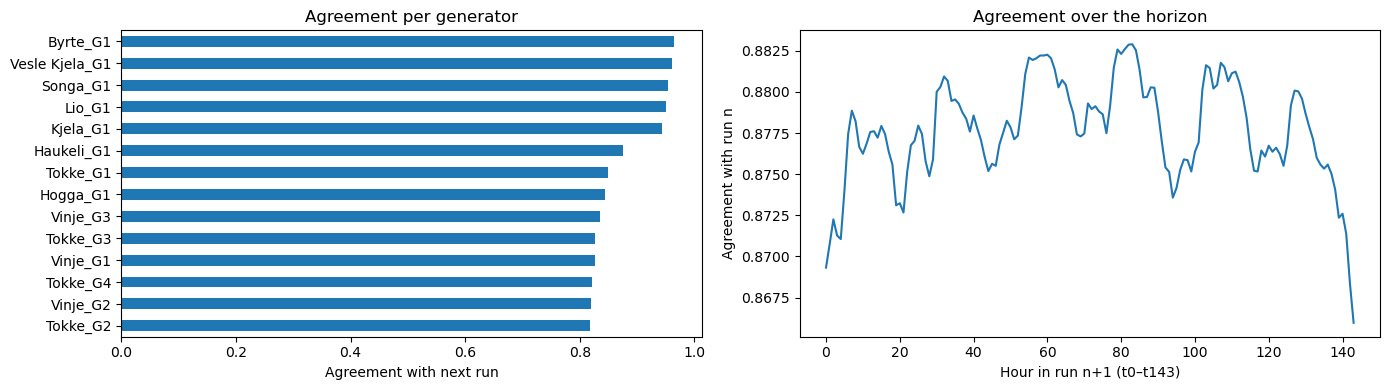

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

agree_per_gen = pd.Series(same.mean(axis=(0, 2)), index=gen_names).sort_values()
agree_per_gen.plot.barh(ax=axes[0])
axes[0].set_xlabel("Agreement with next run")
axes[0].set_title("Agreement per generator")

axes[1].plot(same.mean(axis=(0, 1)))
axes[1].set_xlabel("Hour in run n+1 (t0–t143)")
axes[1].set_ylabel("Agreement with run n")
axes[1].set_title("Agreement over the horizon")

plt.tight_layout()
plt.show()

**Notes 2.2.1**
- Consecutive runs agree on about **88%** of overlapping generator-hours → the plan for a given hour is **revised** from day to day as new information (prices, inflow, volumes) arrives.
- So the target is not one fixed schedule per hour; each run is its own decision given its own inputs.
- TODO: which generators are revised most often? Does agreement depend on how far ahead the hour is?

#### 2.2.2 Run No → date mapping and data coverage

The test file only has `Run No`. Check that the date pattern holds in train, then check that every feature table covers the full test period (last run + 167 hours).

In [9]:
START = pd.Timestamp("2015-01-01")

expected = START + pd.to_timedelta(train["Run No"] - 1, unit="D")
print("Run No -> date pattern holds in train:", (expected == train["starttime"]).all())
print("Gaps between runs:", train["starttime"].diff().value_counts().to_dict())

test["starttime"] = START + pd.to_timedelta(test["Run No"] - 1, unit="D")
need_until = test["starttime"].max() + pd.Timedelta(hours=167)
print(f"Test runs: {test['starttime'].min().date()} -> {test['starttime'].max().date()}")
print(f"Features needed until: {need_until}")

Run No -> date pattern holds in train: True
Gaps between runs: {Timedelta('1 days 00:00:00'): 2921}
Test runs: 2023-01-01 -> 2024-12-25
Features needed until: 2024-12-31 23:00:00


In [10]:
tables = {"price": price, "inflow": inflow, "volume": volume, "water_value": water_value,
          "min_flow": min_flow, "min_volume": min_volume}

for name, df in tables.items():
    first = df["date"].min().tz_convert(None)
    last = df["date"].max().tz_convert(None)
    step = df["date"].diff().value_counts().index[0]
    print(f"{name:12s} {first} -> {last}   main step: {step}   covers test: {last >= need_until}")

price        2015-01-01 00:00:00 -> 2025-12-31 23:45:00   main step: 0 days 01:00:00   covers test: True
inflow       1958-01-01 00:00:00 -> 2025-10-15 07:00:00   main step: 0 days 01:00:00   covers test: True
volume       2015-01-01 00:00:00 -> 2025-01-01 00:00:00   main step: 1 days 00:00:00   covers test: True
water_value  2015-01-01 00:00:00 -> 2025-01-01 00:00:00   main step: 1 days 00:00:00   covers test: True
min_flow     2015-01-01 00:00:00 -> 2025-12-31 23:00:00   main step: 0 days 01:00:00   covers test: True
min_volume   2015-01-01 00:00:00 -> 2025-12-31 23:00:00   main step: 0 days 01:00:00   covers test: True


**Notes 2.2.2**
- Fill in from the output: does the pattern hold (`True`)? Are there any gaps between runs?
- Test covers 2023-01-01 → 2024-12-25; features are needed until 2024-12-31 23:00.
- Volume and water value end on 2025-01-01 → just enough to cover the test period.
- Check the price step: the market changed to 15-minute resolution in late 2025, so the end of the price file may not be hourly (outside our period, but must be handled when resampling – see 5.6).

#### 2.2.3 Optimiser calculation time

`total_calculation_time` tells us how hard each optimisation problem was. Not usable as a feature (missing in test), but it shows when the problem is complex.

count    2922.000000
mean      147.018996
std       333.067145
min        22.406436
25%        39.995748
50%        51.737313
75%        78.254212
max      4525.742015
Name: total_calculation_time, dtype: float64


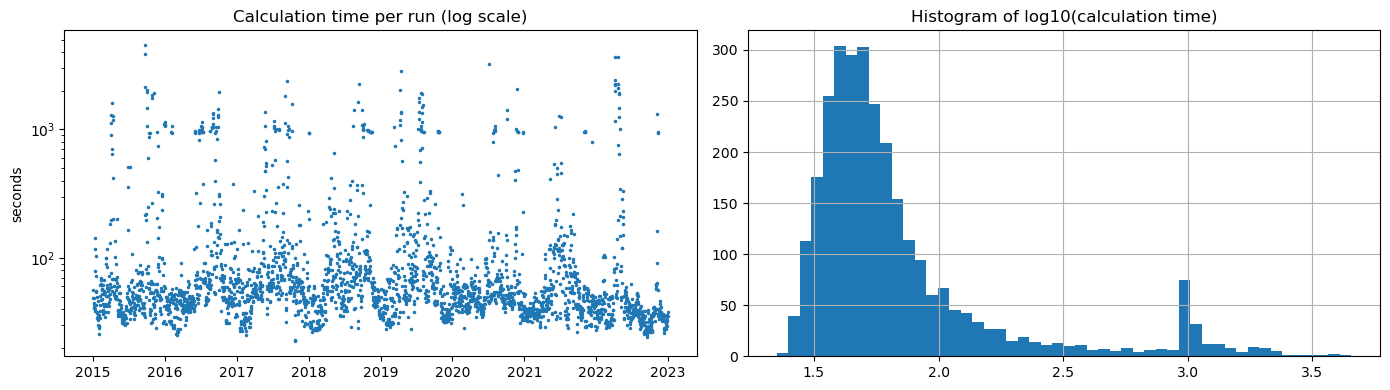

In [11]:
print(train["total_calculation_time"].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(train["starttime"], train["total_calculation_time"], ".", markersize=3)
axes[0].set_yscale("log")
axes[0].set_title("Calculation time per run (log scale)")
axes[0].set_ylabel("seconds")

train["total_calculation_time"].pipe(np.log10).hist(bins=50, ax=axes[1])
axes[1].set_title("Histogram of log10(calculation time)")
plt.tight_layout()
plt.show()

**Notes 2.2.3**
- Median ≈ 52 s, but a long tail up to ≈ 4500 s (over an hour).
- TODO: are the slow runs concentrated in certain periods (e.g. 2022 price crisis, snowmelt)? That would indicate when the decisions are hardest – and possibly hardest to predict.

### 2.3 Is the data intuitive?

*Sanity checks against domain knowledge: volumes within [0, max_vol]? negative prices/inflows? generators on when price is high? any impossible combinations?*

## 3. Exploring individual features

*Lecture tools: `describe()`, histograms, index-vs-value plots, `value_counts()`, `isnull()`.*

### 3.1 Target (unit commitment)

#### 3.1.1 On-rate per generator (class balance)

*`value_counts()` / mean per generator.*

#### 3.1.2 On-rate over the 168-hour horizon (t0–t167)

*Daily/weekly pattern within the plan.*

#### 3.1.3 Seasonal / yearly patterns

*On-rate per month and per year.*

### 3.2 Day-ahead price

*`describe()`, histogram, price over time (index vs value), daily/weekly profile.*

### 3.3 Inflow

*Seasonal profile (snowmelt), long history 1958–2025 vs. 2015–2024.*

### 3.4 Reservoir volume

*Level over time, compare with `max_vol` from topology.*

### 3.5 Water value

*Over time per reservoir, compare with price level.*

### 3.6 Constraints (min flow, min volume)

*When are they active (non-zero)?*

### 3.7 Topology

*Reservoir → plant → generator mapping, p_min/p_max, start costs.*

## 4. Exploring pairs and groups of features

*Lecture tools: scatter plots (coloured by class / train vs test), scatter matrix, correlation matrix, sorted feature statistics.*

### 4.1 Price vs. commitment

*On-rate as a function of price.*

### 4.2 Price vs. water value, coloured by on/off

*Expected key plot: price − water value as decision rule.*

### 4.3 Reservoir volume / inflow vs. commitment

### 4.4 Correlation between generators

*`corr()` + `matshow` on the 14 generators.*

### 4.5 Feature correlations

*Water values across reservoirs, volumes, inflows.*

### 4.6 Groups of target columns

*`df.mean().sort_values().plot(style='.')` over all 2352 target columns.*

### 4.7 Train vs. test distribution shift

*Compare 2015–2022 with 2023–2024 for price, inflow, volume, water value.*

## 5. Data cleaning

### 5.1 Missing values

*`isnull()` per table; if any, understand why before imputing.*

### 5.2 Constant features

*`nunique() == 1` — target columns always 0/1, constraint columns always 0.*

### 5.3 Duplicated features

*`T.drop_duplicates()` — identical generators/columns?*

### 5.4 Duplicated rows / timestamps

*Duplicate or missing hours (e.g. daylight saving).*

### 5.5 Outliers

*Box plots, Z-score, IQR. Decide: real (keep) or error (fix/remove).*

### 5.6 Time alignment

*Hourly vs daily resolution, UTC vs local time.*

## 6. Key findings & implications for modelling

- *...*